# ¿Qué hojas afectadas pasan por sanas?

Revisamos las predicciones fuera de pliegue (OOF) del modelo binario escogido en D-05. Estudiamos la sensibilidad por clase original, la extensión anotada de la roya, el brillo en la foto y las máscaras que delimitan cada hoja. La unidad de conteo es la fotografía; varias pueden corresponder a una misma planta.

Ejecuta el cuaderno desde su carpeta dentro del repositorio. Los archivos de D-05, el inventario y las máscaras COCO se leen de la copia local. El cuaderno lleva adjuntos los registros de la réplica y el ejemplo de la demostración para poder revisarlos sin conexión.

Usamos las mismas herramientas para leer las predicciones, las anotaciones y las fotografías de ejemplo.

In [1]:
import base64
import gzip
import hashlib
import json
from io import BytesIO, StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from skimage.color import rgb2hsv
from skimage.feature import graycomatrix, graycoprops

repo_root = Path("../../..")

Semilla fija del proyecto por si hace falta reproducir algo auxiliar (p. ej. orden de figura).


In [2]:
# Semilla fija del proyecto
seed = 42

seed


42

Carpeta de resultados D-cv-errores y rutas a los tres CSV de D-05 (métricas CV, OOF del ganador y OOF de todos los modelos).


In [3]:
results_dir = Path("../../../experiments/results/rocole/D-cv-errores")
cv_metrics_path = results_dir / "rocole_d05_cv_metrics.csv"
best_oof_path = results_dir / "rocole_d05_best_oof_predictions.csv"
all_oof_path = results_dir / "rocole_d05_oof_predictions.csv"

print("results_dir:", results_dir, "existe:", results_dir.exists())
print("cv_metrics_path existe:", cv_metrics_path.exists())
print("best_oof_path existe:", best_oof_path.exists())
print("all_oof_path existe:", all_oof_path.exists())
results_dir, cv_metrics_path, best_oof_path, all_oof_path


results_dir: ..\..\..\experiments\results\rocole\D-cv-errores existe: True
cv_metrics_path existe: True
best_oof_path existe: True
all_oof_path existe: True


(WindowsPath('../../../experiments/results/rocole/D-cv-errores'),
 WindowsPath('../../../experiments/results/rocole/D-cv-errores/rocole_d05_cv_metrics.csv'),
 WindowsPath('../../../experiments/results/rocole/D-cv-errores/rocole_d05_best_oof_predictions.csv'),
 WindowsPath('../../../experiments/results/rocole/D-cv-errores/rocole_d05_oof_predictions.csv'))

Tabla de métricas CV de D-05 para saber quién ganó por `f1_macro` (sin reabrir el holdout histórico).


In [4]:
cv_metrics = pd.read_csv(cv_metrics_path)

cv_metrics


,model_name,mean_f1_macro,ci95_low,ci95_high,std_f1_macro,fold_0_f1_macro,fold_1_f1_macro,fold_2_f1_macro,fold_3_f1_macro,fold_4_f1_macro
0,logistic,0.741413,0.725481,0.757345,0.012831,0.750613,0.756356,0.726963,0.743451,0.729680
1,random_forest,0.795717,0.777545,0.813889,0.014635,0.776865,0.786751,0.794576,0.809800,0.810595
2,svc,0.767086,0.718602,0.815571,0.039048,0.710443,0.800016,0.760552,0.807764,0.756657


Nombre del ganador según la media CV ya guardada en D-05.


In [5]:
best_model_name = cv_metrics.loc[cv_metrics["mean_f1_macro"].idxmax(), "model_name"]

best_model_name


'random_forest'

Predicciones OOF del ganador (File, planta, etiquetas, fold, `y_true`, `y_pred`, `model_name`).


In [6]:
best_oof_predictions = pd.read_csv(best_oof_path)

print("filas OOF ganador:", len(best_oof_predictions))
best_oof_predictions.head()


filas OOF ganador: 1481


,File,link_group,Binary.Label,Multiclass.Label,fold,y_true,y_pred,model_name
0,C1P1H1.jpg,74,healthy,healthy,0,healthy,healthy,random_forest
1,C1P2E2.jpg,84,unhealthy,rust_level_2,0,unhealthy,unhealthy,random_forest
2,C1P2H1.jpg,84,healthy,healthy,0,healthy,healthy,random_forest
3,C1P3E1.jpg,95,healthy,healthy,1,healthy,healthy,random_forest
4,C1P3E2.jpg,95,unhealthy,rust_level_2,1,unhealthy,unhealthy,random_forest


Comprobamos que `model_name` en el CSV coincide con el ganador de métricas y cuántas hojas hay en el OOF.


In [7]:
oof_model_names = best_oof_predictions["model_name"].unique()
print("model_name en OOF:", oof_model_names)
print("best_model_name:", best_model_name)
print("coincide:", set(oof_model_names) == {best_model_name})
print("n_hojas OOF:", len(best_oof_predictions))


model_name en OOF: ['random_forest']
best_model_name: random_forest
coincide: True
n_hojas OOF: 1481


Solo hojas enfermas: el recall por enfermedad se mide sobre `Binary.Label` / `y_true` == `unhealthy`.


In [8]:
unhealthy_oof_leaves = best_oof_predictions.loc[
    best_oof_predictions["y_true"] == "unhealthy"
].copy()

print("n_unhealthy:", len(unhealthy_oof_leaves))
unhealthy_oof_leaves.head()


n_unhealthy: 723


,File,link_group,Binary.Label,Multiclass.Label,fold,y_true,y_pred,model_name
1,C1P2E2.jpg,84,unhealthy,rust_level_2,0,unhealthy,unhealthy,random_forest
4,C1P3E2.jpg,95,unhealthy,rust_level_2,1,unhealthy,unhealthy,random_forest
6,C1P3H2.jpg,95,unhealthy,rust_level_3,1,unhealthy,unhealthy,random_forest
7,C1P4E2.jpg,103,unhealthy,rust_level_2,4,unhealthy,unhealthy,random_forest
9,C1P4H2.jpg,103,unhealthy,rust_level_2,4,unhealthy,unhealthy,random_forest


Inventario de enfermas por `Multiclass.Label` (red_spider_mite, rust_level_1..4); contrastamos `rust_level_1` con las 333 del índice completo.


In [9]:
unhealthy_multiclass_counts = (
    unhealthy_oof_leaves["Multiclass.Label"]
    .value_counts()
    .rename_axis("Multiclass.Label")
    .reset_index(name="n_leaves")
)

unhealthy_multiclass_counts


,Multiclass.Label,n_leaves
0,rust_level_1,333
1,rust_level_2,157
2,red_spider_mite,155
3,rust_level_3,54
4,rust_level_4,24


Por cada `Multiclass.Label`: total, TP (`y_pred` == unhealthy), FN (`y_pred` == healthy).


In [10]:
multiclass_detection_counts = (
    unhealthy_oof_leaves.groupby("Multiclass.Label", as_index=False)
    .agg(
        n_leaves=("File", "count"),
        tp=("y_pred", lambda s: (s == "unhealthy").sum()),
        fn=("y_pred", lambda s: (s == "healthy").sum()),
    )
)

multiclass_detection_counts


,Multiclass.Label,n_leaves,tp,fn
0,red_spider_mite,155,141,14
1,rust_level_1,333,224,109
2,rust_level_2,157,132,25
3,rust_level_3,54,53,1
4,rust_level_4,24,24,0


Sensibilidad = TP / (TP + FN) por `Multiclass.Label`.


In [11]:
multiclass_sensitivity = multiclass_detection_counts.copy()
multiclass_sensitivity["sensitivity"] = (
    multiclass_sensitivity["tp"]
    / (multiclass_sensitivity["tp"] + multiclass_sensitivity["fn"])
)

multiclass_sensitivity


,Multiclass.Label,n_leaves,tp,fn,sensitivity
0,red_spider_mite,155,141,14,0.909677
1,rust_level_1,333,224,109,0.672673
2,rust_level_2,157,132,25,0.840764
3,rust_level_3,54,53,1,0.981481
4,rust_level_4,24,24,0,1.000000


Fila de `rust_level_1`: n, TP, FN y sensibilidad; es el foco del cuaderno (leve, fácil de confundir con sana).


In [12]:
rust_level_1_sensitivity = multiclass_sensitivity.loc[
    multiclass_sensitivity["Multiclass.Label"] == "rust_level_1"
].copy()

rust_level_1_sensitivity


,Multiclass.Label,n_leaves,tp,fn,sensitivity
1,rust_level_1,333,224,109,0.672673


Contexto opcional: misma sensibilidad multiclass con las columnas OOF de Random Forest (no elige ganador).


In [13]:
all_oof_predictions = pd.read_csv(all_oof_path)

print("filas all OOF:", len(all_oof_predictions))
all_oof_predictions.head()


filas all OOF: 1481


,File,link_group,Binary.Label,Multiclass.Label,fold,pred_logistic,pred_random_forest,pred_svc
0,C1P1H1.jpg,74,healthy,healthy,0,healthy,healthy,unhealthy
1,C1P2E2.jpg,84,unhealthy,rust_level_2,0,unhealthy,unhealthy,unhealthy
2,C1P2H1.jpg,84,healthy,healthy,0,healthy,healthy,healthy
3,C1P3E1.jpg,95,healthy,healthy,1,healthy,healthy,healthy
4,C1P3E2.jpg,95,unhealthy,rust_level_2,1,unhealthy,unhealthy,unhealthy


Filtramos enfermas en el CSV de todos los modelos (misma lógica que el ganador).


In [14]:
unhealthy_all_oof_leaves = all_oof_predictions.loc[
    all_oof_predictions["Binary.Label"] == "unhealthy"
].copy()

print("n_unhealthy all OOF:", len(unhealthy_all_oof_leaves))
unhealthy_all_oof_leaves.head()


n_unhealthy all OOF: 723


,File,link_group,Binary.Label,Multiclass.Label,fold,pred_logistic,pred_random_forest,pred_svc
1,C1P2E2.jpg,84,unhealthy,rust_level_2,0,unhealthy,unhealthy,unhealthy
4,C1P3E2.jpg,95,unhealthy,rust_level_2,1,unhealthy,unhealthy,unhealthy
6,C1P3H2.jpg,95,unhealthy,rust_level_3,1,unhealthy,unhealthy,unhealthy
7,C1P4E2.jpg,103,unhealthy,rust_level_2,4,unhealthy,unhealthy,unhealthy
9,C1P4H2.jpg,103,unhealthy,rust_level_2,4,unhealthy,unhealthy,unhealthy


Por cada `Multiclass.Label` en el OOF de RF: total, TP (`pred_random_forest` == unhealthy), FN (`pred_random_forest` == healthy).


In [15]:
forest_multiclass_detection_counts = (
    unhealthy_all_oof_leaves.groupby("Multiclass.Label", as_index=False)
    .agg(
        n_leaves=("File", "count"),
        tp=("pred_random_forest", lambda s: (s == "unhealthy").sum()),
        fn=("pred_random_forest", lambda s: (s == "healthy").sum()),
    )
)

forest_multiclass_detection_counts


,Multiclass.Label,n_leaves,tp,fn
0,red_spider_mite,155,141,14
1,rust_level_1,333,224,109
2,rust_level_2,157,132,25
3,rust_level_3,54,53,1
4,rust_level_4,24,24,0


Sensibilidad = TP / (TP + FN) por `Multiclass.Label` con las predicciones RF OOF (solo contraste).


In [16]:
forest_multiclass_sensitivity = forest_multiclass_detection_counts.copy()
forest_multiclass_sensitivity["sensitivity"] = (
    forest_multiclass_sensitivity["tp"]
    / (forest_multiclass_sensitivity["tp"] + forest_multiclass_sensitivity["fn"])
)

forest_multiclass_sensitivity


,Multiclass.Label,n_leaves,tp,fn,sensitivity
0,red_spider_mite,155,141,14,0.909677
1,rust_level_1,333,224,109,0.672673
2,rust_level_2,157,132,25,0.840764
3,rust_level_3,54,53,1,0.981481
4,rust_level_4,24,24,0,1.000000


Persistimos la tabla de sensibilidad del ganador con prefijo `rocole_d06_`.


In [17]:
sensitivity_csv_path = results_dir / "rocole_d06_multiclass_sensitivity.csv"
multiclass_sensitivity.to_csv(sensitivity_csv_path, index=False)

print("guardado:", sensitivity_csv_path)
sensitivity_csv_path


guardado: ..\..\..\experiments\results\rocole\D-cv-errores\rocole_d06_multiclass_sensitivity.csv


WindowsPath('../../../experiments/results/rocole/D-cv-errores/rocole_d06_multiclass_sensitivity.csv')

Persistimos la tabla de sensibilidad del RF (contraste) con prefijo `rocole_d06_`.


In [18]:
forest_sensitivity_csv_path = results_dir / "rocole_d06_forest_multiclass_sensitivity.csv"
forest_multiclass_sensitivity.to_csv(forest_sensitivity_csv_path, index=False)

print("guardado:", forest_sensitivity_csv_path)
forest_sensitivity_csv_path


guardado: ..\..\..\experiments\results\rocole\D-cv-errores\rocole_d06_forest_multiclass_sensitivity.csv


WindowsPath('../../../experiments/results/rocole/D-cv-errores/rocole_d06_forest_multiclass_sensitivity.csv')

Figura: sensibilidad por `Multiclass.Label` del ganador, destacando `rust_level_1`.


In [19]:
sensitivity_figure_path = results_dir / "rocole_d06_sensitivity_by_multiclass.png"

plot_order = [
    "red_spider_mite",
    "rust_level_1",
    "rust_level_2",
    "rust_level_3",
    "rust_level_4",
]
plot_table = (
    multiclass_sensitivity.set_index("Multiclass.Label")
    .reindex(plot_order)
    .dropna(subset=["sensitivity"])
    .reset_index()
)

bar_colors = [
    "#c45c26" if label == "rust_level_1" else "#4a7c59"
    for label in plot_table["Multiclass.Label"]
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(plot_table["Multiclass.Label"], plot_table["sensitivity"], color=bar_colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Sensibilidad (recall)")
ax.set_xlabel("Multiclass.Label")
ax.set_title(f"Sensibilidad OOF por multiclass — {best_model_name}")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(sensitivity_figure_path, dpi=150)
plt.close("all")

print("figura:", sensitivity_figure_path)
sensitivity_figure_path


figura: ..\..\..\experiments\results\rocole\D-cv-errores\rocole_d06_sensitivity_by_multiclass.png


WindowsPath('../../../experiments/results/rocole/D-cv-errores/rocole_d06_sensitivity_by_multiclass.png')

## Cobertura y trazabilidad

Cada foto debe aparecer una sola vez en el archivo del ganador y en el inventario curado. Comprobamos que concuerden la clase, el grupo de planta y el pliegue asignado. D-05 repartió todas las fotos curadas en cinco pliegues, incluidas las del test histórico A–C.

In [20]:
featured_dir = repo_root / "data/featured/rocole"
leaf_index = pd.read_csv(featured_dir / "index.csv")
audit = best_oof_predictions.merge(
    leaf_index, on=["File", "link_group", "Binary.Label", "Multiclass.Label"],
    how="outer", validate="one_to_one", indicator=True,
)
assert audit["_merge"].eq("both").all() and audit["File"].is_unique
assert audit["model_name"].eq(best_model_name).all()
assert audit["y_true"].equals(audit["Binary.Label"])
assert set(audit["y_pred"]) == {"healthy", "unhealthy"}
assert audit[["link_group", "fold"]].notna().all().all()
assert audit.groupby("link_group")["fold"].nunique().eq(1).all()
assert audit["fold"].nunique() == 5
audit = audit.drop(columns="_merge")
audit.groupby("fold").agg(fotos=("File", "size"), grupos=("link_group", "nunique"))

,fotos,grupos
fold,,
0,297,71
1,296,71
2,297,72
3,295,71
4,296,72


## ¿Qué extensión de roya se le escapó al modelo?

El experto que etiquetó RoCoLe asignó cuatro bandas de porcentaje de hoja con manchas. Esto permite comparar la extensión anotada de la roya entre aciertos y omisiones. El porcentaje exacto y el tamaño de cada mancha requerirían una anotación adicional. La escala de roya solo se aplica a las fotos etiquetadas como roya. [Parraga-Alava et al., tabla 1](https://pmc.ncbi.nlm.nih.gov/articles/PMC6727496/#tbl1)

In [21]:
rust_area_bands = {
    "rust_level_1": "1–5 %", "rust_level_2": "6–20 %",
    "rust_level_3": "21–50 %", "rust_level_4": ">50 %",
}
audit["rust_area_band"] = audit["Multiclass.Label"].map(rust_area_bands)
severity_table = multiclass_sensitivity.loc[
    multiclass_sensitivity["Multiclass.Label"].isin(rust_area_bands)
].copy()
severity_table.insert(1, "rust_area_band", severity_table["Multiclass.Label"].map(rust_area_bands))
severity_table["fn_rate"] = severity_table["fn"] / severity_table["n_leaves"]
severity_table

,Multiclass.Label,rust_area_band,n_leaves,tp,fn,sensitivity,fn_rate
1,rust_level_1,1–5 %,333,224,109,0.672673,0.327327
2,rust_level_2,6–20 %,157,132,25,0.840764,0.159236
3,rust_level_3,21–50 %,54,53,1,0.981481,0.018519
4,rust_level_4,>50 %,24,24,0,1.000000,0.000000


## Brillo dentro de la hoja

C-02 contó los píxeles de la máscara en cuatro intervalos iguales del canal V de HSV. Representamos cada intervalo por su punto medio y calculamos un promedio entre 0 y 1 por foto. Esta medida aproxima el brillo registrado por la cámara. También depende del color de la hoja y de la exposición; el conjunto carece de mediciones de iluminancia en lux.

In [22]:
value_bins = [f"hsv_v_b{i}" for i in range(4)]
hsv = pd.read_csv(featured_dir / "hsv_hist_features_masked.csv")
assert set(hsv["File"]) == set(audit["File"])
assert hsv["error"].fillna("").str.strip().eq("").all()
fractions = hsv[value_bins].to_numpy()
assert np.all((fractions >= 0) & (fractions <= 1))
assert np.allclose(fractions.sum(axis=1), 1)
hsv["brightness"] = fractions @ np.array([0.125, 0.375, 0.625, 0.875])
audit = audit.merge(hsv[["File", "brightness"]], on="File", validate="one_to_one")
audit.groupby("Binary.Label")["brightness"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
Binary.Label,,,,,,,,
healthy,758.0,0.627,0.070,0.375,0.587,0.631,0.673,0.806
unhealthy,723.0,0.609,0.071,0.350,0.574,0.615,0.650,0.833


## Qué delimitan las máscaras

Leemos la anotación COCO original. La categoría con polígonos delimita la hoja entera. La tabla distingue las categorías declaradas de las que realmente tienen anotaciones en el archivo.

In [23]:
annotation_path = repo_root / "data/raw/RoCoLe/Annotations/RoCoLE-coco.json"
coco = json.loads(annotation_path.read_text(encoding="utf-8"))
categories = pd.DataFrame(coco["categories"]).set_index("id")
annotation_counts = pd.Series([a["category_id"] for a in coco["annotations"]]).value_counts()
categories.assign(n_annotations=annotation_counts.reindex(categories.index, fill_value=0))

,supercategory,name,n_annotations
id,,,
1,Leaf,Leaf,1560
2,classification,classification,0


Identificamos la fotografía de cada contorno por el nombre original al final de la URL de COCO. Exigimos correspondencia única entre foto, identificador COCO y anotación de hoja.

In [24]:
images = pd.DataFrame(coco["images"])[["id", "file_name", "width", "height"]].rename(columns={"id": "image_id"})
images["File"] = images["file_name"].str.rsplit("-", n=1).str[-1]
assert images["File"].notna().all() and images["File"].is_unique
leaf_category = categories.index[categories["name"].eq("Leaf")].item()
annotations = pd.DataFrame(coco["annotations"]).query("category_id == @leaf_category")
masks = images.merge(annotations, on="image_id", how="outer", validate="one_to_one", indicator=True)
assert masks["_merge"].eq("both").all()
assert masks["segmentation"].map(len).eq(1).all()
masks[["File", "width", "height", "area"]].head()

,File,width,height,area
0,C1P1H1.jpg,2048,1152,450606.0
1,C1P2E2.jpg,2048,1152,410188.0
2,C1P2H1.jpg,2048,1152,499729.0
3,C1P3E1.jpg,2048,1152,450191.0
4,C1P3E2.jpg,2048,1152,445705.0


## Calidad geométrica del contorno

Detectamos cruces o contactos entre lados que no son vecinos. Excluimos los extremos compartidos por dos lados consecutivos y el cierre del anillo. Un contorno que se cruza merece revisión visual aunque su área publicada sea positiva.

In [25]:
def has_edge_intersection(vertices):
    ends = np.roll(vertices, -1, axis=0)
    first, second = np.triu_indices(len(vertices), k=2)
    keep = ~((first == 0) & (second == len(vertices) - 1))
    a, b = vertices[first[keep]], ends[first[keep]]
    c, d = vertices[second[keep]], ends[second[keep]]

    def orientation(start, end, point):
        edge, offset = end - start, point - start
        return edge[:, 0] * offset[:, 1] - edge[:, 1] * offset[:, 0]

    overlapping_boxes = np.all(
        np.maximum(np.minimum(a, b), np.minimum(c, d))
        <= np.minimum(np.maximum(a, b), np.maximum(c, d)), axis=1,
    )
    crosses_ab = orientation(a, b, c) * orientation(a, b, d) <= 0
    crosses_cd = orientation(c, d, a) * orientation(c, d, b) <= 0
    return bool(np.any(overlapping_boxes & crosses_ab & crosses_cd))

Medimos cuánto encuadre ocupa la hoja y revisamos si el polígono se sale de la imagen, toca su borde o discrepa del área guardada. Usamos las coordenadas continuas de COCO, que admiten el límite superior de la imagen. Tocar el marco también puede corresponder al encuadre de la foto.

In [26]:
geometry_records = []
for mask in masks.itertuples(index=False):
    vertices = np.asarray(mask.segmentation[0], dtype=float).reshape(-1, 2)
    if np.array_equal(vertices[0], vertices[-1]):
        vertices = vertices[:-1]
    assert len(vertices) >= 3 and np.isfinite(vertices).all()
    width_height = np.array([mask.width, mask.height])
    x, y = vertices.T
    polygon_area = abs(x @ np.roll(y, 1) - y @ np.roll(x, 1)) / 2
    geometry_records.append({
        "File": mask.File,
        "leaf_frame_fraction": polygon_area / (mask.width * mask.height),
        "touches_frame": bool(np.any((vertices == 0) | (vertices == width_height))),
        "outside_frame": bool(np.any((vertices < 0) | (vertices > width_height))),
        "area_mismatch": not np.isclose(polygon_area, mask.area, rtol=0, atol=1),
        "self_intersection": has_edge_intersection(vertices),
    })
geometry = pd.DataFrame(geometry_records)
assert set(audit["File"]).issubset(geometry["File"])
audit = audit.merge(geometry, on="File", validate="one_to_one")
audit["nonpositive_area"] = audit["leaf_frame_fraction"].le(0)
audit[["self_intersection", "outside_frame", "area_mismatch", "touches_frame", "nonpositive_area"]].sum()

self_intersection      6
outside_frame          0
area_mismatch          0
touches_frame        270
nonpositive_area       0
dtype: int64

## Falsos negativos con su denominador

En las fotos afectadas, cada grupo compara omisiones (FN) con detecciones correctas (TP). Los cuartiles de brillo describen las 1.481 fotografías. Repetimos el contraste en roya nivel 1 para comparar imágenes dentro de una misma banda. La tasa es FN/(FN+TP); las comparaciones describen asociaciones y conservan el modelo elegido en D-05.

In [27]:
audit["brightness_band"], brightness_limits = pd.qcut(
    audit["brightness"], 4, labels=["Q1", "Q2", "Q3", "Q4"], retbins=True,
)
audit["is_fn"] = audit["y_true"].eq("unhealthy") & audit["y_pred"].eq("healthy")
affected = audit.loc[audit["y_true"].eq("unhealthy")].copy()
early_rust = affected.loc[affected["Multiclass.Label"].eq("rust_level_1")]
descriptive_tables = []
for cohort, leaves in [("unhealthy", affected), ("rust_level_1", early_rust)]:
    for variable in ["brightness_band", "leaf_face", "touches_frame", "self_intersection", "fold"]:
        grouped = leaves.groupby(variable, observed=True).agg(
            n_images=("File", "size"), n_groups=("link_group", "nunique"), fn=("is_fn", "sum"),
        ).rename_axis("stratum").reset_index()
        grouped["tp"] = grouped["n_images"] - grouped["fn"]
        grouped["fn_rate"] = grouped["fn"] / grouped["n_images"]
        descriptive_tables.append(grouped.assign(cohort=cohort, variable=variable))
error_profile = pd.concat(descriptive_tables, ignore_index=True)
print("Límites de brillo, de Q1 a Q4:", np.round(brightness_limits, 3))
error_profile.query("variable == 'brightness_band'").round(3)

Límites de brillo, de Q1 a Q4: [0.35  0.58  0.623 0.665 0.833]


,stratum,n_images,n_groups,fn,tp,fn_rate,cohort,variable
0,Q1,200,160,30,170,0.150,unhealthy,brightness_band
1,Q2,207,169,39,168,0.188,unhealthy,brightness_band
2,Q3,179,145,37,142,0.207,unhealthy,brightness_band
3,Q4,137,121,43,94,0.314,unhealthy,brightness_band
15,Q1,100,85,22,78,0.220,rust_level_1,brightness_band
16,Q2,96,85,31,65,0.323,rust_level_1,brightness_band
17,Q3,81,67,28,53,0.346,rust_level_1,brightness_band
18,Q4,56,50,28,28,0.500,rust_level_1,brightness_band


La figura resume dos contrastes históricos. A la izquierda se lee el porcentaje de omisiones por extensión de roya; a la derecha, por brillo dentro del nivel 1. Cada barra indica errores/fotos afectadas. Los dos paneles comparten escala.

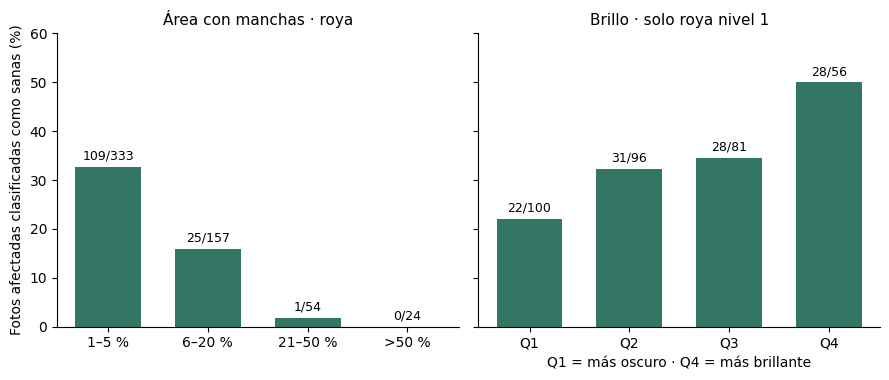

In [28]:
early_brightness = error_profile.query("cohort == 'rust_level_1' and variable == 'brightness_band'")
figure, axes = plt.subplots(1, 2, figsize=(9, 3.9), sharey=True)
panels = [
    (severity_table["rust_area_band"], severity_table, "Área con manchas · roya", "n_leaves"),
    (early_brightness["stratum"], early_brightness, "Brillo · solo roya nivel 1", "n_images"),
]
for axis, (labels, table, title, total_column) in zip(axes, panels):
    bars = axis.bar(labels, table["fn_rate"] * 100, color="#347665", width=0.66)
    counts = [f"{fn}/{total}" for fn, total in zip(table["fn"], table[total_column])]
    axis.bar_label(bars, labels=counts, padding=3, fontsize=9)
    axis.set_title(title, fontsize=11)
    axis.set_ylim(0, 60)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Fotos afectadas clasificadas como sanas (%)")
axes[1].set_xlabel("Q1 = más oscuro · Q4 = más brillante")
figure.tight_layout()
figure.savefig(results_dir / "rocole_d06_fn_severidad_brillo.png", dpi=150, bbox_inches="tight")
plt.show()

Cuantificamos cuántos grupos acumulan omisiones y cuántos contienen a la vez detecciones correctas y errores. La tasa por grupo siempre conserva el número de fotos afectadas disponibles.

In [29]:
plant_errors = affected.groupby("link_group").agg(
    n_images=("File", "size"), fn=("is_fn", "sum"), fold=("fold", "first"),
)
plant_errors["tp"] = plant_errors["n_images"] - plant_errors["fn"]
plant_errors["fn_rate"] = plant_errors["fn"] / plant_errors["n_images"]
print("Grupos con fotos afectadas:", len(plant_errors))
print("Grupos con uno o más FN:", plant_errors["fn"].gt(0).sum())
print("Grupos con FN y TP:", ((plant_errors["fn"] > 0) & (plant_errors["tp"] > 0)).sum())
plant_errors.groupby("fn").size().rename("grupos")

Grupos con fotos afectadas: 345
Grupos con uno o más FN: 115
Grupos con FN y TP: 92


fn
0    230
1     85
2     27
3      2
4      1
Name: grupos, dtype: int64

Estimamos la incertidumbre de la sensibilidad OOF del modelo escogido. Remuestreamos grupos completos con reemplazo 2.000 veces y tomamos los percentiles 2,5 y 97,5. Mantenemos fijas las predicciones. Los intervalos describen variación entre grupos de esta muestra y omiten la incertidumbre por volver a entrenar o elegir el modelo.

In [30]:
groups = np.sort(audit["link_group"].unique())
rng = np.random.default_rng(seed)
group_draws = rng.integers(len(groups), size=(2000, len(groups)))
interval_records = []
for cohort, leaves in [("unhealthy", affected), ("rust_level_1", early_rust)]:
    totals = leaves.groupby("link_group")["is_fn"].agg(["size", "sum"]).reindex(groups, fill_value=0)
    sample_n = totals["size"].to_numpy()[group_draws].sum(axis=1)
    sample_fn = totals["sum"].to_numpy()[group_draws].sum(axis=1)
    estimates = 1 - sample_fn[sample_n > 0] / sample_n[sample_n > 0]
    low, high = np.quantile(estimates, [0.025, 0.975])
    interval_records.append({
        "cohort": cohort, "n_images": len(leaves), "n_groups": leaves["link_group"].nunique(),
        "sensitivity": 1 - leaves["is_fn"].mean(), "ci95_low": low, "ci95_high": high,
    })
sensitivity_intervals = pd.DataFrame(interval_records)
sensitivity_intervals.round(3)

,cohort,n_images,n_groups,sensitivity,ci95_low,ci95_high
0,unhealthy,723,345,0.794,0.761,0.824
1,rust_level_1,333,203,0.673,0.616,0.725


## Casos que el equipo puede revisar

Sobreponemos el contorno de COCO a cuatro fotos ya incluidas en la sustentación. Dos son de roya nivel 1 con decisiones opuestas. Las coordenadas se escalan al tamaño de la copia. Esta muestra dirigida sirve para inspeccionar los contornos y contrastar casos; su acuerdo visual no estima la calidad de todas las máscaras.

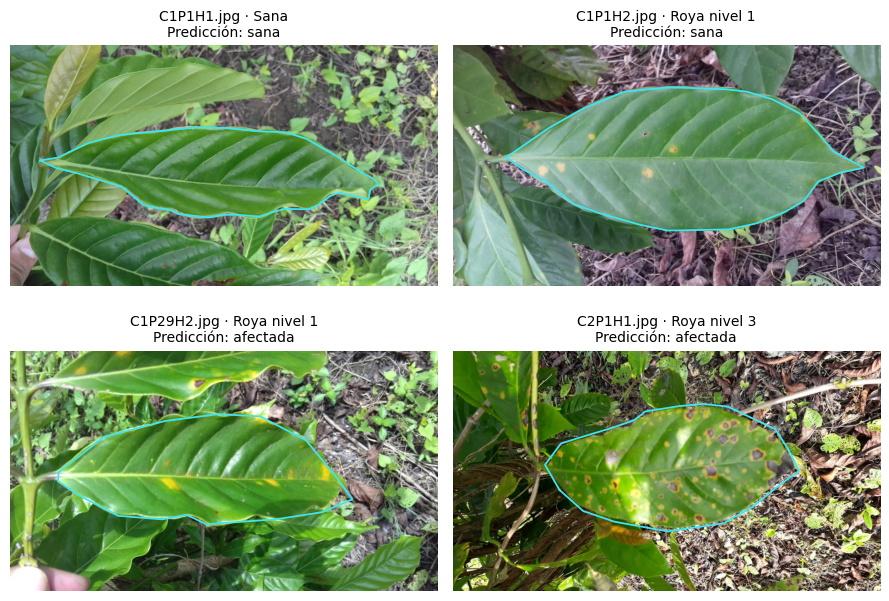

In [31]:
examples = ["C1P1H1.jpg", "C1P1H2.jpg", "C1P29H2.jpg", "C2P1H1.jpg"]
photo_dir = repo_root / "slides/sustentacion-rocole/composition/assets/figuras"
review_cases = audit.set_index("File").loc[examples].join(
    masks.set_index("File")[["segmentation", "width", "height"]], validate="one_to_one",
)
class_names = {"healthy": "Sana", "rust_level_1": "Roya nivel 1", "rust_level_3": "Roya nivel 3"}
figure, axes = plt.subplots(2, 2, figsize=(9, 6.5))
for axis, (file_name, case) in zip(axes.flat, review_cases.iterrows()):
    photo = plt.imread(photo_dir / file_name)
    vertices = np.asarray(case["segmentation"][0]).reshape(-1, 2)
    scale = [photo.shape[1] / case["width"], photo.shape[0] / case["height"]]
    outline = np.vstack([vertices, vertices[0]]) * scale
    axis.imshow(photo)
    axis.plot(*outline.T, color="#41e3ef", linewidth=1.3)
    predicted = "sana" if case["y_pred"] == "healthy" else "afectada"
    title = f"{file_name} · {class_names[case['Multiclass.Label']]}"
    axis.set_title(title + chr(10) + f"Predicción: {predicted}", fontsize=10)
    axis.axis("off")
figure.tight_layout()
figure.savefig(results_dir / "rocole_d06_casos_mascara.png", dpi=145, bbox_inches="tight")
plt.show()

Guardamos las filas que respaldan el análisis. La tabla por fotografía permite localizar cada FN, su banda de extensión, su brillo, las señales geométricas y su grupo. Las tablas resumidas conservan los denominadores.

In [32]:
case_columns = [
    "File", "plant_key", "link_group", "fold", "leaf_face", "Multiclass.Label", "y_true",
    "y_pred", "is_fn", "rust_area_band", "brightness", "brightness_band",
    "leaf_frame_fraction", "touches_frame", "self_intersection", "outside_frame",
    "area_mismatch", "nonpositive_area",
]
audit[case_columns].to_csv(results_dir / "rocole_d06_auditoria_fotos.csv", index=False)
error_profile.to_csv(results_dir / "rocole_d06_perfil_fn.csv", index=False)
plant_errors.to_csv(results_dir / "rocole_d06_fn_por_grupo.csv")
severity_table.to_csv(results_dir / "rocole_d06_extension_roya.csv", index=False)
sensitivity_intervals.to_csv(results_dir / "rocole_d06_ic_sensibilidad.csv", index=False)
print("Fotos auditadas:", len(audit), "| Fotos afectadas:", len(affected), "| FN:", affected["is_fn"].sum())

Fotos auditadas: 1481 | Fotos afectadas: 723 | FN: 149


## ¿Se mantiene la dificultad con otro agrupamiento?

La auditoría reconstruyó componentes que enlazan plantas a partir de los 67 pares históricos de archivos duplicados. La réplica del bosque produjo una predicción fuera de pliegue para cada una de las 1.481 fotos. Aquí leemos el registro guardado de esa corrida y comparamos ambas predicciones por foto. Los cinco pliegues y el ajuste de hiperparámetros se calcularon en la réplica original.

La hoja de datos adjunta guarda los resultados por foto en un CSV comprimido. Comprobamos su huella SHA-256 antes de leerlos. Verificamos también la correspondencia entre fotos y la asignación de cada componente a un solo pliegue.
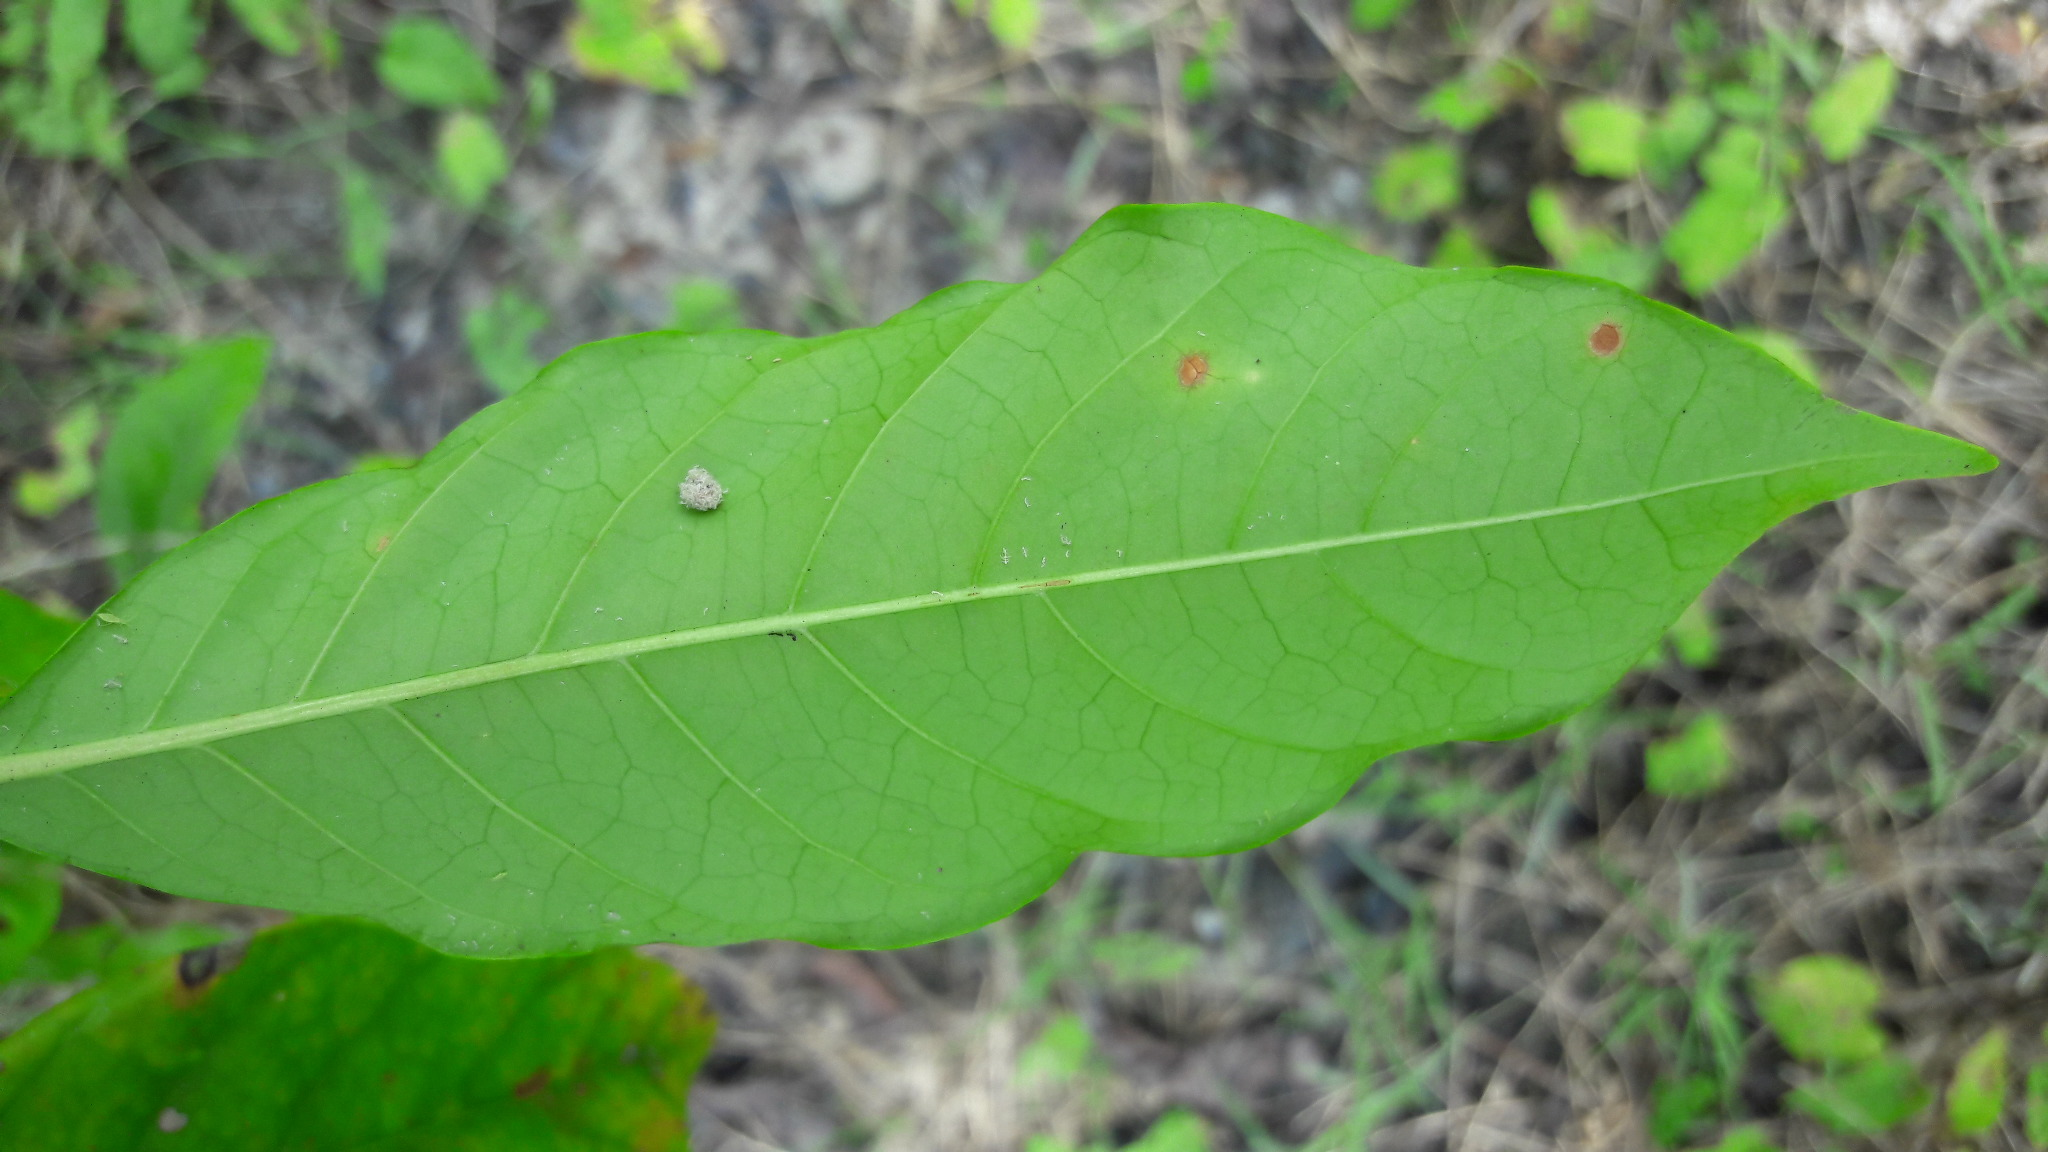
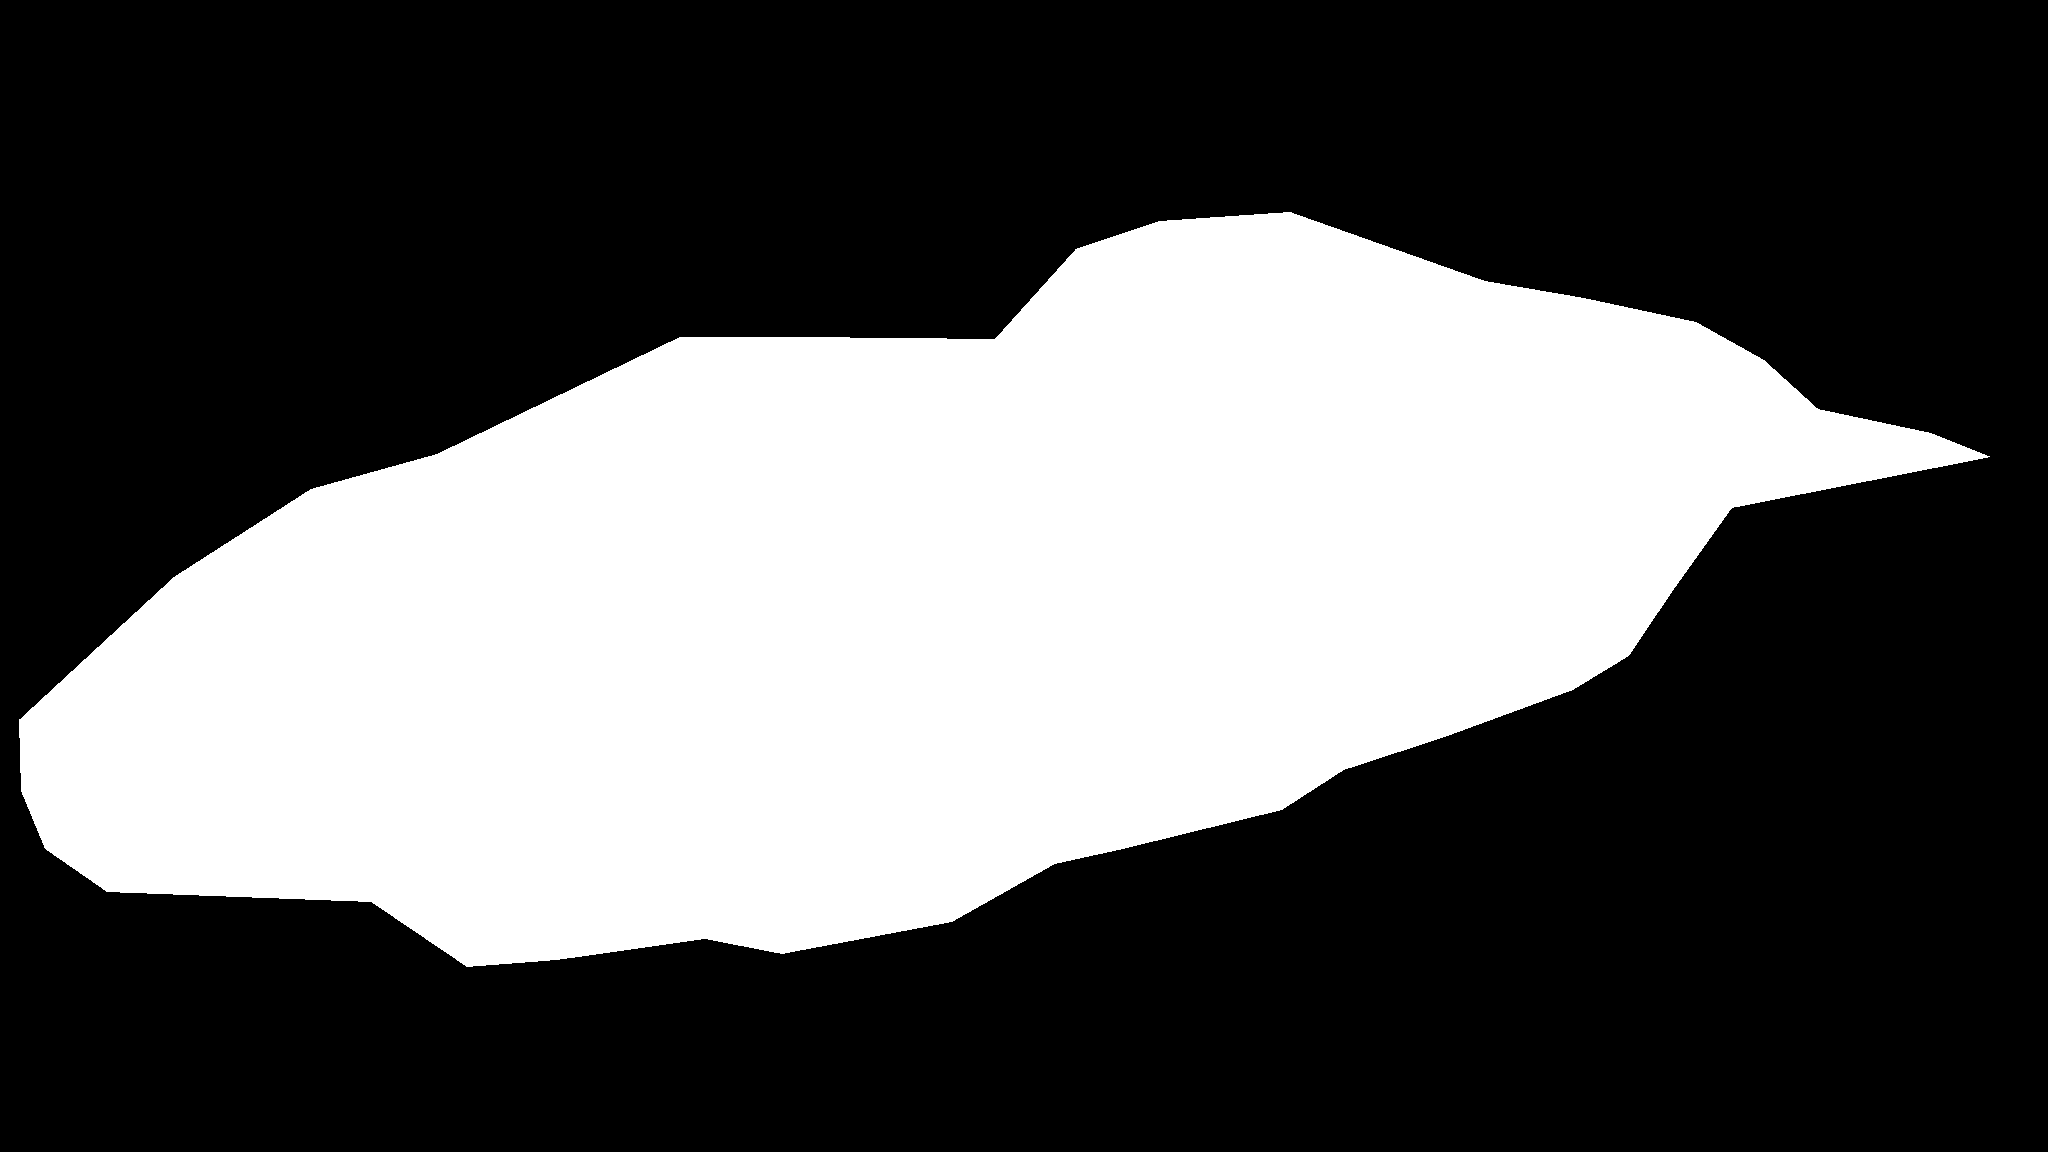

In [33]:
notebook_path = Path("06-sensibilidad-multiclass-c.ipynb")
with notebook_path.open(encoding="utf-8") as notebook_file:
    notebook_cells = json.load(notebook_file)["cells"]
attachment_groups = [cell["attachments"] for cell in notebook_cells if "predicciones_por_foto.csv.gz" in cell.get("attachments", {})]
if len(attachment_groups) != 1:
    raise ValueError("El cuaderno debe contener una copia del registro de la réplica.")
attachments = attachment_groups[0]

def verified_attachment(name, mime, expected_sha256, *, compressed=False):
    raw = base64.b64decode(attachments[name][mime], validate=True)
    content = gzip.decompress(raw) if compressed else raw
    if hashlib.sha256(content).hexdigest() != expected_sha256:
        raise ValueError(f"La huella del recurso {name} difiere de la registrada.")
    return content

revised_bytes = verified_attachment(
    "predicciones_por_foto.csv.gz", "application/gzip",
    "1349603a535ef31fbb2502ac9f89a4fe3b8593a81416a89fda5a873959ff62c8",
    compressed=True,
)
revised = pd.read_csv(BytesIO(revised_bytes))
assert revised["File"].is_unique and set(revised["File"]) == set(audit["File"])
assert not revised[["component", "fold_revisado", "prediction"]].isna().any().any()
assert revised.groupby("component")["fold_revisado"].nunique().eq(1).all()
assert set(revised["prediction"]) == {"healthy", "unhealthy"}
comparison = audit.merge(
    revised, on=["File", "link_group", "plant_key", "Binary.Label", "Multiclass.Label"],
    how="outer", validate="one_to_one", indicator=True,
)
assert comparison["_merge"].eq("both").all()
comparison["fn_revised"] = comparison["prediction"].eq("healthy") & comparison["y_true"].eq("unhealthy")
reviewed_rates = comparison.loc[comparison["y_true"].eq("unhealthy")].groupby("Multiclass.Label").agg(
    n_images=("File", "size"), original_fn=("is_fn", "sum"), revised_fn=("fn_revised", "sum"),
)
reviewed_rates["original_sensitivity"] = 1 - reviewed_rates["original_fn"] / reviewed_rates["n_images"]
reviewed_rates["revised_sensitivity"] = 1 - reviewed_rates["revised_fn"] / reviewed_rates["n_images"]
reviewed_rates.to_csv(results_dir / "rocole_d06_sensibilidad_agrupacion_revisada.csv")
reviewed_rates.round(3)

,n_images,original_fn,revised_fn,original_sensitivity,revised_sensitivity
Multiclass.Label,,,,,
red_spider_mite,155,14,14,0.910,0.910
rust_level_1,333,109,103,0.673,0.691
rust_level_2,157,25,23,0.841,0.854
rust_level_3,54,1,2,0.981,0.963
rust_level_4,24,0,0,1.000,1.000


Completamos la comparación para las seis etiquetas originales. Para la fila sana, un acierto significa que la predicción fue sana (especificidad del clasificador binario). Para cada enfermedad, significa que la hoja se reconoció como afectada. El modelo nunca predijo la especie de ácaro o el nivel de roya.

In [34]:
comparison["correct_original"] = comparison["y_pred"].eq(comparison["y_true"])
comparison["correct_revised"] = comparison["prediction"].eq(comparison["y_true"])
class_accuracy = comparison.groupby(["Multiclass.Label", "y_true"]).agg(
    n_images=("File", "size"), original_correct=("correct_original", "sum"),
    revised_correct=("correct_revised", "sum"),
)
class_accuracy["original_fraction_correct"] = class_accuracy["original_correct"] / class_accuracy["n_images"]
class_accuracy["revised_fraction_correct"] = class_accuracy["revised_correct"] / class_accuracy["n_images"]
class_accuracy.to_csv(results_dir / "rocole_d06_aciertos_seis_clases.csv")
class_accuracy.round(3)

,,n_images,original_correct,revised_correct,original_fraction_correct,revised_fraction_correct
Multiclass.Label,y_true,,,,,
healthy,healthy,758,605,609,0.798,0.803
red_spider_mite,unhealthy,155,141,141,0.910,0.910
rust_level_1,unhealthy,333,224,230,0.673,0.691
rust_level_2,unhealthy,157,132,134,0.841,0.854
rust_level_3,unhealthy,54,53,52,0.981,0.963
rust_level_4,unhealthy,24,24,24,1.000,1.000


## De las predicciones guardadas a una foto nueva

El equipo registró una prueba del formulario con seis fotos de la partición histórica de prueba, una por etiqueta original. El registro de doce respuestas se conserva en la siguiente celda, con las clases y puntajes originales. La demostración de este cuaderno puede ejecutarse de forma local en los mismos dos modos. A recibe la foto completa. C recibe además una máscara de la hoja.

In [35]:
recorded_csv = """File,split,link_group,referencia_original,referencia_binaria,prediccion,acierto,puntaje_bosque,version
C10P13E1.jpg,test,4,healthy,sana,afectada,False,0.6554,rocole-a-rgb-glcm-v1
C10P13E1.jpg,test,4,healthy,sana,sana,True,0.65,rocole-c-leaf-rgb-glcm-hsv-v1
C10P13E2.jpg,test,4,red_spider_mite,afectada,sana,False,0.5348,rocole-a-rgb-glcm-v1
C10P13E2.jpg,test,4,red_spider_mite,afectada,afectada,True,0.62,rocole-c-leaf-rgb-glcm-hsv-v1
C10P13H2.jpg,test,4,rust_level_2,afectada,afectada,True,0.5458,rocole-a-rgb-glcm-v1
C10P13H2.jpg,test,4,rust_level_2,afectada,afectada,True,0.79,rocole-c-leaf-rgb-glcm-hsv-v1
C11P37H2.jpg,test,49,rust_level_3,afectada,afectada,True,0.7713,rocole-a-rgb-glcm-v1
C11P37H2.jpg,test,49,rust_level_3,afectada,afectada,True,0.86,rocole-c-leaf-rgb-glcm-hsv-v1
C11P38H2.jpg,test,50,rust_level_4,afectada,sana,False,0.5505,rocole-a-rgb-glcm-v1
C11P38H2.jpg,test,50,rust_level_4,afectada,afectada,True,0.7,rocole-c-leaf-rgb-glcm-hsv-v1
C12P15E2.jpg,test,61,rust_level_1,afectada,sana,False,0.6219,rocole-a-rgb-glcm-v1
C12P15E2.jpg,test,61,rust_level_1,afectada,sana,False,0.61,rocole-c-leaf-rgb-glcm-hsv-v1
"""
expected_digest = "6acd2bacc51bcc862051812e185e715c6715a66c052f4605d8c55cccc0fc904e"
assert hashlib.sha256(recorded_csv.encode("utf-8")).hexdigest() == expected_digest
demo = pd.read_csv(StringIO(recorded_csv))
mode_names = {"rocole-a-rgb-glcm-v1": "Foto sola (A)", "rocole-c-leaf-rgb-glcm-hsv-v1": "Con máscara (C)"}
disease_names = {
    "healthy": "Sana", "red_spider_mite": "Ácaro rojo", "rust_level_1": "Roya nivel 1",
    "rust_level_2": "Roya nivel 2", "rust_level_3": "Roya nivel 3", "rust_level_4": "Roya nivel 4",
}
assert not demo.duplicated(["File", "version"]).any() and demo["File"].nunique() == 6
assert demo.groupby("File")["version"].apply(lambda versions: set(versions) == set(mode_names)).all()
demo["Modo"] = demo["version"].map(mode_names)
demo["Referencia"] = demo["referencia_original"].map(disease_names)
demo["Foto"] = demo["File"]
assert demo["Referencia"].notna().all() and demo["Referencia"].nunique() == 6
demo.pivot(index=["Foto", "Referencia"], columns="Modo", values="prediccion")[list(mode_names.values())]

,Modo,Foto sola (A),Con máscara (C)
Foto,Referencia,,
C10P13E1.jpg,Sana,afectada,sana
C10P13E2.jpg,Ácaro rojo,sana,afectada
C10P13H2.jpg,Roya nivel 2,afectada,afectada
C11P37H2.jpg,Roya nivel 3,afectada,afectada
C11P38H2.jpg,Roya nivel 4,sana,afectada
C12P15E2.jpg,Roya nivel 1,sana,sana


### Preparar los dos bosques de la demostración

Reproducimos en memoria las configuraciones de A-04 y C-04 con las 1.037 fotos del entrenamiento histórico. A usa siete características de la foto completa y C añade las 16 medidas HSV de la hoja delimitada. Conservamos el orden de las columnas de los cuadernos originales.

In [36]:
rgb_columns = [
    "exg_mean", "exg_std", "ngrdi_mean", "ngrdi_std",
    "glcm_contrast", "glcm_homogeneity", "glcm_energy",
]
hsv_columns = [f"hsv_{channel}_b{i}" for channel, count in (("h", 8), ("s", 4), ("v", 4)) for i in range(count)]
a_features = pd.read_csv(featured_dir / "rgb_glcm_features.csv")[["File", *rgb_columns]]
c_features = pd.read_csv(featured_dir / "rgb_glcm_features_masked.csv")[["File", *rgb_columns]]
c_features = c_features.merge(hsv[["File", *hsv_columns]], on="File", validate="one_to_one")
training_index = leaf_index.loc[leaf_index["split"].eq("train"), ["File", "Binary.Label"]]
assert len(training_index) == 1037 and training_index["File"].is_unique
models = {}
for protocol, measures, depth in [("A", a_features, 10), ("C", c_features, None)]:
    training = training_index.merge(measures, on="File", how="left", validate="one_to_one")
    columns = rgb_columns if protocol == "A" else [*rgb_columns, *hsv_columns]
    features = training[columns].to_numpy()
    assert np.isfinite(features).all()
    forest = RandomForestClassifier(n_estimators=100, max_depth=depth, class_weight="balanced", random_state=seed)
    models[protocol] = forest.fit(features, training["Binary.Label"])
print(f"Dos bosques entrenados sobre {len(training_index)} fotos del conjunto de entrenamiento.")

Dos bosques entrenados sobre 1037 fotos del conjunto de entrenamiento.


Para transformar una foto en las medidas de los bosques seguimos A-02 y C-02. El extractor resume el color y la textura. Si recibe una máscara del mismo tamaño, calcula las características sobre la hoja delimitada. [Extractor A-02](../A-full/02-caracteristicas-rocole.ipynb) · [Extractor C-02](../C-hsv-masked/02-caracteristicas-rocole-hsv-masked.ipynb)

In [37]:
def rocole_image_features(img: Image.Image, leaf_mask: np.ndarray | None = None) -> np.ndarray:
    """Reproduce A-02 con foto completa, o B/C-02 si se facilita la máscara de hoja."""
    rgb = img.convert("RGB")
    # Acumular por franjas evita mantener varias copias grandes de la foto en memoria.
    channels = np.asarray(rgb)
    if leaf_mask is not None and (leaf_mask.shape != channels.shape[:2] or not leaf_mask.any()):
        raise ValueError("La máscara debe tener el tamaño de la foto y contener píxeles de hoja.")
    totals = np.zeros(2)
    squared = np.zeros(2)
    histograms = [np.zeros(count, dtype=int) for count in (8, 4, 4)]
    for offset in range(0, channels.shape[0], 128):
        stripe = channels[offset:offset + 128]
        if leaf_mask is not None:
            stripe = stripe[leaf_mask[offset:offset + 128]]
            if not stripe.size:
                continue
            hsv = rgb2hsv(stripe.astype(np.float64) / 255.0)
            for i, histogram in enumerate(histograms):
                histogram += np.histogram(hsv[:, i], bins=len(histogram), range=(0.0, 1.0))[0]
        red, green, blue = stripe.reshape(-1, 3).astype(np.float64).T
        channel_sum = red + green + blue + 1e-8
        exg = 2 * (green / channel_sum) - red / channel_sum - blue / channel_sum
        ngrdi = (green - red) / (green + red + 1e-8)
        for i, measure in enumerate((exg, ngrdi)):
            totals[i] += measure.sum()
            squared[i] += np.square(measure).sum()
    pixels = rgb.width * rgb.height if leaf_mask is None else leaf_mask.sum()
    means = totals / pixels
    stds = np.sqrt(np.maximum(squared / pixels - np.square(means), 0))
    gray = np.asarray(rgb.convert("L"), dtype=np.uint16)
    if leaf_mask is not None:
        rows = np.flatnonzero(leaf_mask.any(axis=1))
        cols = np.flatnonzero(leaf_mask.any(axis=0))
        bounds = np.s_[rows[0]:rows[-1]+1, cols[0]:cols[-1]+1]
        gray = np.where(leaf_mask[bounds], gray[bounds], 0)
    levels = (gray * 31 // 255).astype(np.uint8)
    matrix = graycomatrix(levels, distances=[1], angles=[0], levels=32)
    texture = [graycoprops(matrix, name)[0, 0] for name in ("contrast", "homogeneity", "energy")]
    measures = np.array([means[0], stds[0], means[1], stds[1], *texture])
    if leaf_mask is None:
        return measures
    return np.concatenate([measures, *(histogram / pixels for histogram in histograms)])

### Elegir una foto

La foto adjunta, C12P15E2.jpg, está etiquetada como roya nivel 1. Se conserva el JPEG original y una máscara PNG de la hoja generada a partir del polígono COCO de RoCoLe. El SHA-256 del JPEG coincide con el archivo de la edición 2 del conjunto de datos. Créditos a Jorge Parraga-Alava, Kevin Cusme, Angélica Loor y Esneider Santander. Licencia CC BY 4.0. [RoCoLe v2 y licencia](https://data.mendeley.com/datasets/c5yvn32dzg/2) · [JPEG original en Mendeley](https://data.mendeley.com/public-files/datasets/c5yvn32dzg/files/4a509681-a940-43ab-840c-e1ff4bb3ca43/file_downloaded)

Para probar la misma foto en modo C, cambia `mask_input = None` por `mask_input = sample_mask`. Para una foto propia usa `photo_input = Path("mi-foto.jpg")`. Si tienes su máscara, indica `mask_input = Path("mi-mascara.png")`, con hoja blanca sobre fondo negro y las mismas dimensiones que la foto.

In [38]:
sample_photo = verified_attachment(
    "C12P15E2.jpg", "image/jpeg", "fcf7208d74c2d93ff41726a74fc79ee947bc60bdbdaad72f34572d880733efab",
)
sample_mask = verified_attachment(
    "C12P15E2.png", "image/png", "3a9ff929d57b4644177e881ef008d7b78bb6b4eed1d663995af224a6df6c5dfa",
)
photo_input = sample_photo
mask_input = None
print("Foto:", "C12P15E2.jpg" if photo_input is sample_photo else str(photo_input))
print("Modo:", "A · foto completa" if mask_input is None else "C · con máscara")

Foto: C12P15E2.jpg
Modo: A · foto completa


Aplicamos el bosque correspondiente al modo elegido. En el ejemplo se puede contrastar la predicción recién calculada con la prueba histórica del formulario. El puntaje es la probabilidad que asigna el bosque a su predicción binaria.

In [39]:
leaf_mask = None
if mask_input is not None:
    mask_source = BytesIO(mask_input) if isinstance(mask_input, bytes) else mask_input
    with Image.open(mask_source) as mask_image:
        leaf_mask = np.asarray(mask_image.convert("L")) > 0
photo_source = BytesIO(photo_input) if isinstance(photo_input, bytes) else photo_input
with Image.open(photo_source) as photo:
    row = rocole_image_features(photo, leaf_mask).reshape(1, -1)
selected_mode = "A" if leaf_mask is None else "C"
forest = models[selected_mode]
scores = forest.predict_proba(row)[0]
predicted_label = forest.classes_[scores.argmax()]
spanish_labels = {"healthy": "sana", "unhealthy": "afectada"}
print("Clase predicha:", spanish_labels[predicted_label])
print("Modo:", selected_mode)
print(f"Puntaje del bosque para la clase predicha: {scores.max():.3f}")
print("El resultado es binario. La roya leve puede pasar por sana.")

Clase predicha: sana
Modo: A
Puntaje del bosque para la clase predicha: 0.622
El resultado es binario. La roya leve puede pasar por sana.


## Conclusiones

- **La roya leve concentra las omisiones.** En las predicciones históricas, el bosque detectó 224 de 333 fotos de roya nivel 1 (67,3 %, IC del 95 % por grupo 61,6–72,5 %). De las 149 fotos afectadas clasificadas como sanas, 109 tenían entre 1 y 5 % de la hoja con manchas. En nivel 4 detectó las 24 fotos disponibles. En la réplica que reunió plantas enlazadas por duplicados, el nivel 1 siguió siendo el más difícil: 230 de 333 detectadas y 103 de las 142 omisiones. El cambio de pliegues impide interpretar esa diferencia como mejora del clasificador.
- **El brillo ayuda a localizar casos para revisión.** Entre las fotos de roya nivel 1, el modelo histórico pasó por alto 22 de 100 en el cuartil más oscuro y 28 de 56 en el más brillante. El brillo se midió dentro de la máscara y también formó parte de las características del modelo. Estos datos no permiten atribuir las omisiones a la iluminación ambiental.
- **Los contornos también tienen limitaciones.** Seis de las 1.481 máscaras curadas se cruzan a sí mismas y 270 alcanzan el borde de la imagen. Todas tienen área positiva, coordenadas dentro del marco y área coherente con el polígono. La hoja ocupa una mediana del 24,9 % del encuadre. En las cuatro fotos revisadas, el contorno sigue la hoja principal. Para cuantificar el acuerdo píxel a píxel o el tamaño de cada mancha se necesitarían delineaciones de referencia adicionales.
- **El error se distribuye entre plantas.** De los 345 grupos históricos con fotos afectadas, 115 tienen alguna omisión y 92 combinan detecciones con omisiones. Son resultados sobre fotos de RoCoLe con máscaras disponibles. Una validación en otra finca permitiría comprobar si se reproducen la sensibilidad y los patrones de error.